In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
import matplotlib
from matplotlib import gridspec

# Add project root to path
sys.path.append(os.path.abspath('../../'))
from BWM.bwm_functions import *

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 7
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica'],
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})


In [2]:
def plot_probe_trajectory(eid, directory_path='../Data2'):
    clusters_path = os.path.join(directory_path, eid, 'clusters.pkl')
    if not os.path.exists(clusters_path):
        print(f"File not found: {clusters_path}")
        return

    clusters = pd.read_pickle(clusters_path)
    xyz = clusters[['x', 'y', 'z']].values
    xyz = xyz[~np.isnan(xyz).any(axis=1)]
    
    if len(xyz) == 0:
        print("No valid XYZ coordinates found.")
        return

    # Map clusters to regions
    cluster_to_region = dict(zip(clusters.cluster_id, clusters.acronym))
    unique_regions = sorted(list(set(cluster_to_region.values())))
    
    print(f"Probe for EID {eid} passed through regions: {', '.join(unique_regions)}")
    return unique_regions


In [6]:
def plot_raster(eid1, eid2=None, directory_path='../Data2', start_time=None, end_time=None, fig=None, gs_sub=None):
    # If eid2 is provided, we will stack two rasters for panel a.
    # If eid2 is None, we use eid1 for everything as before.
    
    eid_for_densmap = eid1
    
    def get_data(eid):
        spikes_path = os.path.join(directory_path, eid, 'spikes.pkl')
        trials_path = os.path.join(directory_path, eid, 'trials.pkl')
        clusters_path = os.path.join(directory_path, eid, 'clusters.pkl')
        
        if not os.path.exists(spikes_path) or not os.path.exists(trials_path) or not os.path.exists(clusters_path):
            print(f"Required files not found for EID: {eid}")
            return None
            
        spikes = pd.read_pickle(spikes_path)
        trials = pd.read_pickle(trials_path)
        clusters = pd.read_pickle(clusters_path)
        return spikes, trials, clusters

    data1 = get_data(eid1)
    if data1 is None: return
    spikes1, trials1, clusters1 = data1
    
    if eid2:
        data2 = get_data(eid2)
        if data2 is None: return
        spikes2, trials2, clusters2 = data2
    else:
        spikes2, trials2, clusters2 = None, None, None

    def process_spikes(spikes, trials, clusters, start_time, end_time):
        spike_times = spikes['times']
        spike_clusters = spikes['clusters']
        
        stim_on_times = trials['stimOn_times'].values
        stim_on_times = stim_on_times[~np.isnan(stim_on_times)]

        if start_time is not None or end_time is not None:
            mask = np.ones_like(spike_times, dtype=bool)
            if start_time is not None: mask &= (spike_times >= start_time)
            if end_time is not None: mask &= (spike_times <= end_time)
            spike_times = spike_times[mask]
            spike_clusters = spike_clusters[mask]
            if start_time is not None: stim_on_times = stim_on_times[stim_on_times >= start_time]
            if end_time is not None: stim_on_times = stim_on_times[stim_on_times <= end_time]

        clusters['beryl'] = br.id2acronym(clusters['atlas_id'], mapping='Beryl')
        clusters = clusters[~clusters['beryl'].isin(['root', 'void'])]
        clusters_sorted = clusters.sort_values(['beryl', 'depths'], ascending=[True, False]).reset_index(drop=True)
        clusters_sorted['plot_coord'] = clusters_sorted.index
        id_to_coord = {cid: coord for cid, coord in zip(clusters_sorted.cluster_id, clusters_sorted.plot_coord)}
        spike_coords = np.array([id_to_coord.get(c, -1) for c in spike_clusters])
        valid_mask = spike_coords != -1
        return spike_times[valid_mask], spike_coords[valid_mask], stim_on_times, clusters, clusters_sorted, id_to_coord

    st1, sc1, son1, c1, cs1, i2c1 = process_spikes(spikes1, trials1, clusters1, start_time, end_time)
    if eid2:
        st2, sc2, son2, c2, cs2, i2c2 = process_spikes(spikes2, trials2, clusters2, start_time, end_time)

    if fig is None:
        fig = plt.figure(figsize=(8.5, 6))
        gs_parent = gridspec.GridSpec(1, 1, figure=fig)
        gs_sub = gs_parent[0]
    
    gs_main = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs_sub, height_ratios=[2, 1], hspace=0.4)
    gs_top = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_main[0], width_ratios=[2, 1], wspace=0.2)
    
    # Raster Group: Split into two vertically if eid2 exists
    if eid2:
        gs_raster_area = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs_top[0], hspace=0.1)
        gs_raster_group1 = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_raster_area[0], width_ratios=[0.05, 1], wspace=0.05)
        gs_raster_group2 = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_raster_area[1], width_ratios=[0.05, 1], wspace=0.05)
        ax_bar1 = fig.add_subplot(gs_raster_group1[0])
        ax_raster1 = fig.add_subplot(gs_raster_group1[1])
        ax_bar2 = fig.add_subplot(gs_raster_group2[0])
        ax_raster2 = fig.add_subplot(gs_raster_group2[1])
        raster_axes = [(ax_bar1, ax_raster1, cs1, st1, sc1, son1, eid1), (ax_bar2, ax_raster2, cs2, st2, sc2, son2, eid2)]
    else:
        gs_raster_group = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_top[0], width_ratios=[0.05, 1], wspace=0.05)
        ax_bar1 = fig.add_subplot(gs_raster_group[0])
        ax_raster1 = fig.add_subplot(gs_raster_group[1])
        raster_axes = [(ax_bar1, ax_raster1, cs1, st1, sc1, son1, eid1)]

    ax_densmap = fig.add_subplot(gs_top[1])
    gs_bottom = gridspec.GridSpecFromSubplotSpec(1, 4, subplot_spec=gs_main[1], wspace=0.3)
    axes_neurons = [fig.add_subplot(gs_bottom[i]) for i in range(4)]
    ax_neuron1 = axes_neurons[0]
    
    # Use union of regions for color mapping consistency if needed, but per-plot is fine
    all_clusters = pd.concat([c1, c2]) if eid2 else c1
    unique_regions = sorted(all_clusters['beryl'].unique())
    region_to_color = {region: plt.cm.Set2(i % 8) for i, region in enumerate(unique_regions)}

    for ax_bar, ax_raster, cs, st, sc, son, eid in raster_axes:
        ax_raster.scatter(st, sc, s=1, c='black', marker='|', alpha=0.5, lw=0.05)
        for _, row in cs.iterrows():
            ax_bar.barh(row['plot_coord'], 1, color=region_to_color[row['beryl']], height=1.0, edgecolor='none')
        
        # Region labels
        u_regs = sorted(cs['beryl'].unique())
        for region in u_regs:
            region_indices = cs[cs['beryl'] == region].index
            if len(region_indices) > 0:
                diffs = np.diff(region_indices)
                breaks = np.where(diffs > 1)[0]
                start_idx = 0
                for b in list(breaks) + [len(region_indices) - 1]:
                    block = region_indices[start_idx:b+1]
                    mid_pos = np.mean(block)
                    ax_bar.text(-0.5, mid_pos, region, va='center', ha='right', fontsize=6)
                    start_idx = b + 1
        
        ax_bar.set_ylim(-0.5, len(cs) - 0.5)
        ax_bar.set_xlim(-1, 1)
        ax_bar.axis('off')
        for t in son:
            ax_raster.axvspan(t, t + 0.5, color='gray', alpha=0.3, lw=0)
        if start_time is not None or end_time is not None:
            ax_raster.set_xlim(left=start_time, right=end_time)
        ax_raster.set_ylim(-0.5, len(cs) - 0.5)
        ax_raster.set_xlabel('Time (s)', fontsize=6)
        ax_raster.tick_params(axis='x', labelsize=6)
        ax_raster.set_yticks([])
        ax_raster.set_yticklabels([])

    # Panel C & DensMAP use both EIDs if available
    res_matrix1, cond_matrix1, cluster_ids1 = get_aligned_response_matrix(
        spikes1, c1, trials1, event='stimOn_times', conditions=['choice'], 
        n_steps=100, step=0.005, stride=0.05, n_pseudo=25, min_trials_per_condition=10,
        mapping_col='beryl', return_cluster_ids=True
    )
    
    if eid2:
        res_matrix2, cond_matrix2, cluster_ids2 = get_aligned_response_matrix(
            spikes2, c2, trials2, event='stimOn_times', conditions=['choice'], 
            n_steps=100, step=0.005, stride=0.05, n_pseudo=25, min_trials_per_condition=10,
            mapping_col='beryl', return_cluster_ids=True
        )
        # Combine matrices if they have compatible shapes
        if res_matrix1.shape[1] == res_matrix2.shape[1] and np.array_equal(cond_matrix1[0], cond_matrix2[0]):
            res_matrix = np.concatenate([res_matrix1, res_matrix2], axis=3)
            cluster_ids = np.concatenate([cluster_ids1, cluster_ids2])
            cond_matrix = cond_matrix1
            # Keep track of which neuron belongs to which EID for mapping back to coordinates
            is_from_eid2 = np.array([False] * len(cluster_ids1) + [True] * len(cluster_ids2))
        else:
            print("Warning: EID1 and EID2 have incompatible conditions for merging. Using EID1 only.")
            res_matrix, cond_matrix, cluster_ids = res_matrix1, cond_matrix1, cluster_ids1
            is_from_eid2 = np.array([False] * len(cluster_ids1))
    else:
        res_matrix, cond_matrix, cluster_ids = res_matrix1, cond_matrix1, cluster_ids1
        is_from_eid2 = np.array([False] * len(cluster_ids1))
    
    # Select example neurons (from combined pool)
    if res_matrix.shape[3] >= 4:
        mean_fr = np.mean(res_matrix, axis=(0, 1, 2))
        active_neurons = np.where(mean_fr >= 1.0)[0]
        if len(active_neurons) < 4: active_neurons = np.arange(res_matrix.shape[3])
        active_cluster_ids = cluster_ids[active_neurons]
        active_regions = []
        filtered_active_neurons = []
        for i, cid in enumerate(active_cluster_ids):
            source_c = c2 if is_from_eid2[active_neurons[i]] else c1
            matches = source_c[source_c['cluster_id'] == cid]['beryl']
            if not matches.empty:
                region = matches.iloc[0]
                if region != 'void':
                    active_regions.append(region)
                    filtered_active_neurons.append(active_neurons[i])
        active_neurons = filtered_active_neurons
        
        found_different = False
        if len(set(active_regions)) >= 4:
            from collections import defaultdict
            region_to_indices = defaultdict(list)
            for i, region in enumerate(active_regions):
                region_to_indices[region].append(active_neurons[i])
            available_regions = list(region_to_indices.keys())
            selected_regions = np.random.choice(available_regions, 4, replace=False)
            selected_indices = np.array([np.random.choice(region_to_indices[r]) for r in selected_regions])
            found_different = True
        if not found_different:
            selected_indices = np.random.choice(active_neurons, min(4, len(active_neurons)), replace=False)
        
        example_cluster_ids = cluster_ids[selected_indices]
        example_coords = []
        example_colors = []
        for idx in selected_indices:
            cid = cluster_ids[idx]
            source_i2c = i2c2 if is_from_eid2[idx] else i2c1
            source_c = c2 if is_from_eid2[idx] else c1
            
            coord = source_i2c.get(cid) or source_i2c.get(int(cid)) or source_i2c.get(float(cid))
            example_coords.append(coord)
            if coord is not None:
                matches = source_c[source_c['cluster_id'] == cid]['beryl']
                if not matches.empty:
                    region = matches.iloc[0]
                    example_colors.append(region_to_color.get(region, 'black'))
                else:
                    example_colors.append('black')
            else:
                example_colors.append('black')
        
        for i, (coord, color) in enumerate(zip(example_coords, example_colors)):
            if coord is not None:
                idx = selected_indices[i]
                target_ax = ax_raster2 if is_from_eid2[idx] else ax_raster1
                target_st = st2 if is_from_eid2[idx] else st1
                target_sc = sc2 if is_from_eid2[idx] else sc1
                mask = target_sc == coord
                target_ax.scatter(target_st[mask], target_sc[mask], s=1, c=color, marker='|', alpha=1.0, lw=0.25)

        # Update right-side labels for both rasters if they have selected neurons
        for ax_r, is_eid2 in [(ax_raster1, False), (ax_raster2, True if eid2 else False)]:
            if is_eid2 and not eid2: continue
            ax_r_right = ax_r.twinx()
            ax_r_right.set_ylim(ax_r.get_ylim())
            relevant_indices = [i for i, idx in enumerate(selected_indices) if is_from_eid2[idx] == is_eid2 and example_coords[i] is not None]
            if relevant_indices:
                ax_r_right.set_yticks([example_coords[i] for i in relevant_indices])
                ax_r_right.set_yticklabels([f"{selected_indices[i]}" for i in relevant_indices], fontsize=5)
            else:
                ax_r_right.set_yticks([])
            ax_r_right.axis('off')

        all_z_values = []
        neuron_dfs = []
        for neuron_idx in selected_indices:
            z_neuron = res_matrix[:, :, :, neuron_idx]
            z_neuron = (z_neuron - np.mean(z_neuron)) / (np.std(z_neuron) + 1e-8)
            all_z_values.append(z_neuron)
            rows = []
            for p in range(z_neuron.shape[0]):
                for c in range(z_neuron.shape[1]):
                    for t in range(z_neuron.shape[2]):
                        rows.append({'pseudo_trial': p, 'condition': cond_matrix[0, c, 0], 't': t * 0.005, 'z': z_neuron[p, c, t]})
            neuron_dfs.append(pd.DataFrame(rows))
            
        global_ymin = min([z.min() for z in all_z_values])
        global_ymax = max([z.max() for z in all_z_values])
        y_range = global_ymax - global_ymin
        global_ymin -= 0.05 * y_range
        global_ymax += 0.05 * y_range

        import seaborn as sns
        for i, (ax, neuron_idx, df_neuron) in enumerate(zip(axes_neurons, selected_indices, neuron_dfs)):
            cid = cluster_ids[neuron_idx]
            source_c = c2 if is_from_eid2[neuron_idx] else c1
            matches = source_c[source_c['cluster_id'] == cid]['beryl']
            if not matches.empty:
                region = matches.iloc[0]
                title_color = region_to_color.get(region, "black")
            else:
                title_color = "black"
            sns.lineplot(data=df_neuron, ax=ax, x='t', y='z', hue='condition', units='pseudo_trial', estimator=None, legend=False, lw=0.25, alpha=0.3, palette=sns.husl_palette(2))
            sns.lineplot(data=df_neuron, ax=ax, x='t', y='z', hue='condition', legend=False, lw=1, alpha=1.0, palette=sns.husl_palette(2))
            ax.set_title(f"{neuron_idx}", fontsize=6, color=title_color, pad=2)
            ax.spines['bottom'].set_position(('data', 0))
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.set_xlabel('Time (s)', fontsize=6)
            ax.set_ylim(global_ymin, global_ymax)
            if i == 0:
                ax.set_ylabel('z-score', fontsize=6)
                ax.tick_params(axis='both', which='major', labelsize=5)
            else:
                ax.set_ylabel('')
                ax.set_yticklabels([])
                ax.tick_params(axis='x', which='major', labelsize=5)
                ax.tick_params(axis='y', which='major', labelsize=0, left=True)
        
        ax_raster1.text(-0.1, 1.05, 'a', transform=ax_raster1.transAxes, fontsize=10, fontweight='bold', va='top', ha='right')
        ax_densmap.text(-0.1, 1.05, 'b', transform=ax_densmap.transAxes, fontsize=10, fontweight='bold', va='top', ha='right')
        ax_neuron1.text(-0.1, 1.05, 'c', transform=ax_neuron1.transAxes, fontsize=10, fontweight='bold', va='top', ha='right')
        
        # --- DensMAP Projection (CP neurons only) ---
        cp_neuron_indices = []
        for i, cid in enumerate(cluster_ids):
            source_c = c2 if is_from_eid2[i] else c1
            matches = source_c[source_c['cluster_id'] == cid]['beryl']
            if not matches.empty and matches.iloc[0] == 'CP':
                cp_neuron_indices.append(i)
        
        if len(cp_neuron_indices) > 2:
            import umap
            res_matrix_cp = res_matrix[:, :, :, cp_neuron_indices]
            mean_res = np.mean(res_matrix_cp, axis=0) 
            mean_res_norm = (mean_res - np.mean(mean_res, axis=(0, 1), keepdims=True)) / (np.std(mean_res, axis=(0, 1), keepdims=True) + 1e-8)
            X_pop = mean_res_norm.reshape(-1, mean_res_norm.shape[2])
            X_neurons = X_pop.T
            X_densmap_input = X_neurons / (np.linalg.norm(X_neurons, axis=1, keepdims=True) + 1e-8)
            
            reducer = umap.UMAP(densmap=True, dens_lambda=2, n_neighbors=min(30, X_densmap_input.shape[0]-1))
            embedding = reducer.fit_transform(X_densmap_input)
            
            ax_densmap.scatter(embedding[:, 0], embedding[:, 1], c='gray', s=1, alpha=0.25)
            
            # Highlight selected neurons if they are in CP
            for idx_in_all, color in zip(selected_indices, example_colors):
                if idx_in_all in cp_neuron_indices:
                    idx_in_cp = cp_neuron_indices.index(idx_in_all)
                    ax_densmap.scatter(embedding[idx_in_cp, 0], embedding[idx_in_cp, 1], c=[color], s=10, alpha=1.0, edgecolors='white', linewidths=0.5)
                    ax_densmap.text(embedding[idx_in_cp, 0] + 0.1, embedding[idx_in_cp, 1] + 0.1, f"{idx_in_all}", fontsize=6, fontweight='bold', color=color)
        else:
            ax_densmap.text(0.5, 0.5, 'Not enough CP neurons', ha='center', va='center')

        ax_densmap.set_xlabel('DensMAP 1', fontsize=6)
        ax_densmap.set_ylabel('DensMAP 2', fontsize=6)
        ax_densmap.set_xticks([]); ax_densmap.set_yticks([])
        for spine in ax_densmap.spines.values(): spine.set_visible(False)

        if gs_sub is None:
            os.makedirs('../Figures', exist_ok=True)
            fig_path = os.path.join('../Figures', f'BWMSchematic_{eid1}.jpg')
            fig.savefig(fig_path, dpi=600, bbox_inches='tight')
            print(f"Figure saved to {fig_path}")

    if gs_sub is None: plt.show()
    return fig


Selected EIDs for panel a: 626126d5-eecf-4e9b-900e-ec29a17ece07, d2f5a130-b981-4546-8858-c94ae1da75ff


/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_2146/2095106864.py:213: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  target_ax.scatter(target_st[mask], target_sc[mask], s=1, c=color, marker='|', alpha=1.0, lw=0.25)


Combined figure saved to ../Figures/BWMSchematic_multi_eid.jpg


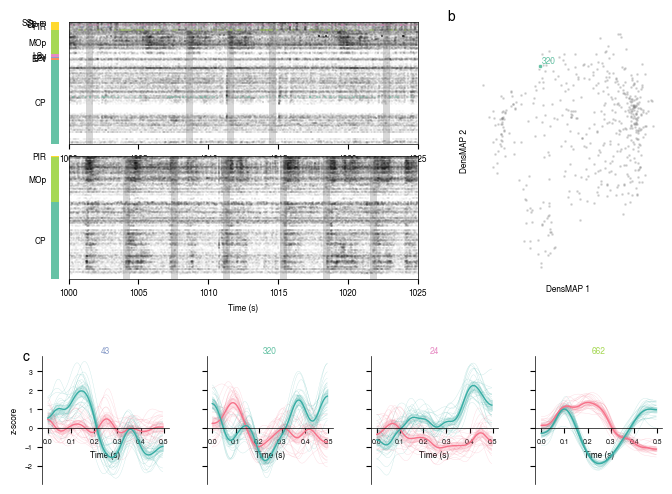

In [7]:
import os
import random

data_path = '../Data2/'
# EIDs that contain CP (found earlier)
cp_eids = ['626126d5-eecf-4e9b-900e-ec29a17ece07', 'd2f5a130-b981-4546-8858-c94ae1da75ff']
eid1, eid2 = cp_eids[0], cp_eids[1]
print(f"Selected EIDs for panel a: {eid1}, {eid2}")

# Create a figure
fig = plt.figure(figsize=(8, 6))
gs_main = gridspec.GridSpec(1, 1, figure=fig)

plot_raster(eid1, eid2, start_time=1000, end_time=1025, fig=fig, gs_sub=gs_main[0])

# Save the combined plot
os.makedirs('../Figures', exist_ok=True)
fig_path = os.path.join('../Figures', f'BWMSchematic_multi_eid.jpg')
fig.savefig(fig_path, dpi=600, bbox_inches='tight')
print(f"Combined figure saved to {fig_path}")

plt.show()
